<a href="https://colab.research.google.com/github/vikramsingh456/ai-ml/blob/dev/EmployeeTurnoverAnalytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Libraries Loaded Successfully ---
=== TASK 1: DATA QUALITY CHECKS ===
Initial Dataset Shape: (14999, 10)

Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB
None

Missing Values per Column:
satisfaction_level       0
last_evaluation         

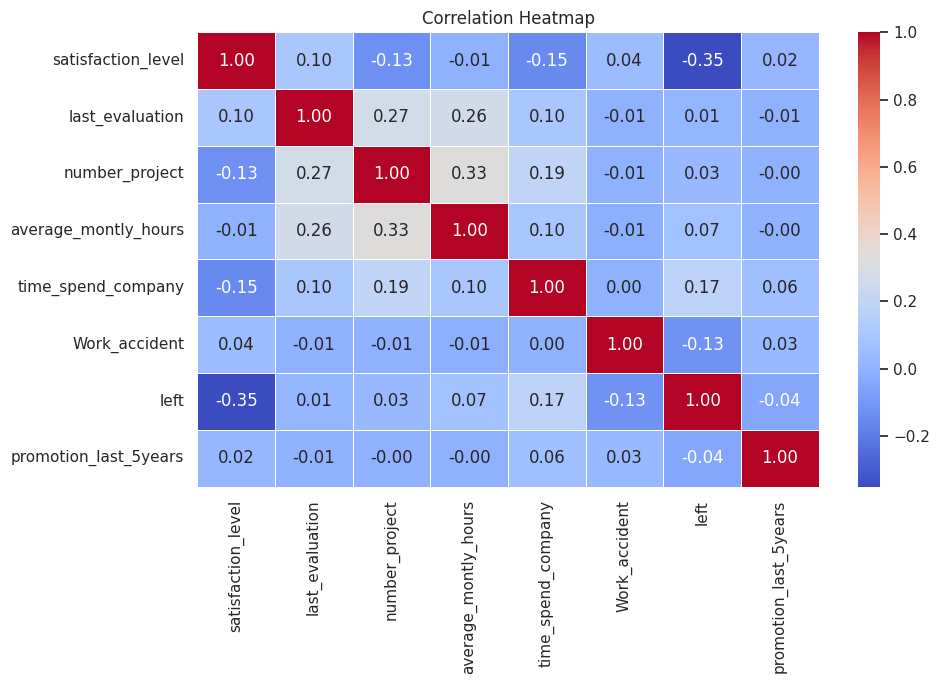

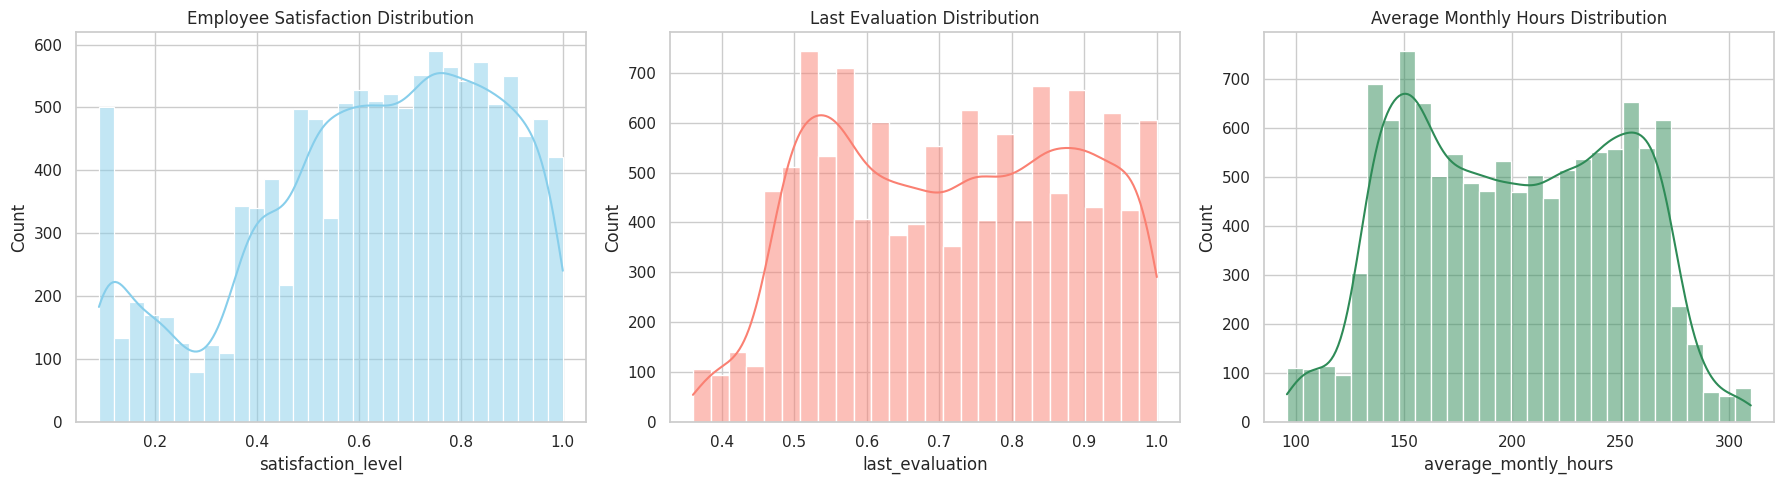

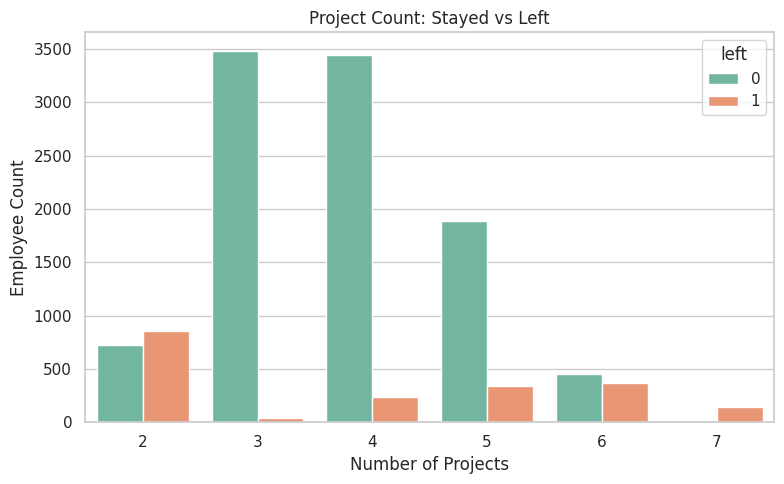


=== TASK 3: CLUSTERING EMPLOYEES WHO LEFT ===


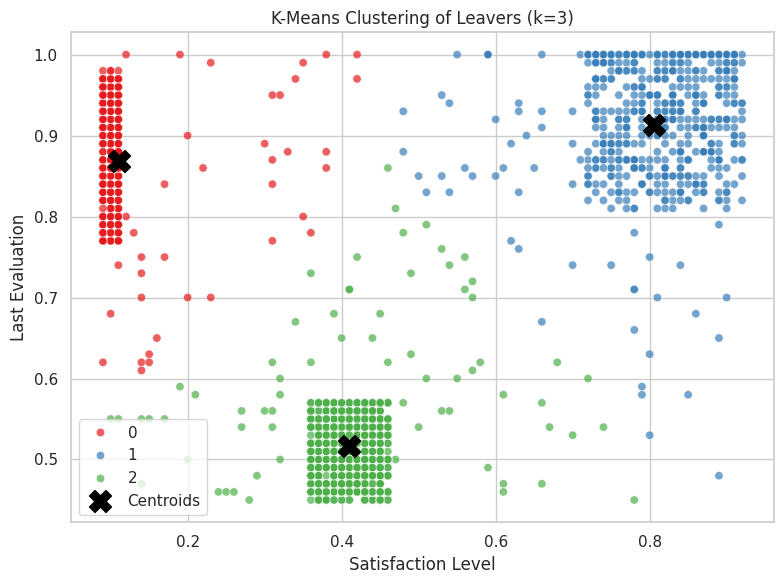


Cluster Profiles:
        satisfaction_level       last_evaluation      
                      mean count            mean count
cluster                                               
0                 0.111199   534        0.869064   534
1                 0.805874   555        0.912577   555
2                 0.410133   902        0.517195   902

=== TASK 4: ENCODING & SMOTE BALANCING ===
Dataset shape after encoding: (11991, 21)
xTrain shape: (9592, 20), xTest shape: (2399, 20)
Class counts before SMOTE in train set:
 left
0    7999
1    1593
Name: count, dtype: int64
Class counts after SMOTE in train set:
 left
0    7999
1    7999
Name: count, dtype: int64

=== TASK 5: 5-FOLD CROSS-VALIDATION TRAINING ===

--- Model: Logistic Regression ---


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


5-Fold CV Recall Scores: [0.855 0.842 0.868 0.853 0.834]
Mean CV Recall: 0.850 (+/- 0.011)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Classification Report (CV):
              precision    recall  f1-score   support

           0       0.85      0.86      0.86      7999
           1       0.86      0.85      0.85      7999

    accuracy                           0.85     15998
   macro avg       0.85      0.85      0.85     15998
weighted avg       0.85      0.85      0.85     15998


--- Model: Random Forest ---
5-Fold CV Recall Scores: [0.967 0.971 0.969 0.959 0.961]
Mean CV Recall: 0.965 (+/- 0.004)
Classification Report (CV):
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      7999
           1       0.99      0.97      0.98      7999

    accuracy                           0.98     15998
   macro avg       0.98      0.98      0.98     15998
weighted avg       0.98      0.98      0.98     15998


--- Model: Gradient Boosting ---
5-Fold CV Recall Scores: [0.951 0.948 0.944 0.942 0.938]
Mean CV Recall: 0.944 (+/- 0.005)
Classification Report (CV):
              pr

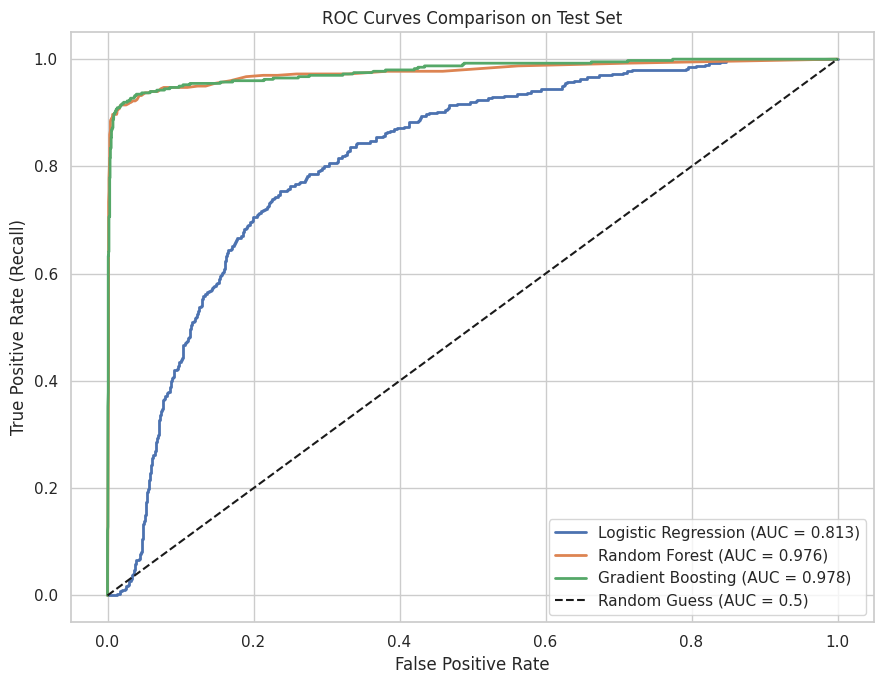


Confusion Matrix for Logistic Regression:


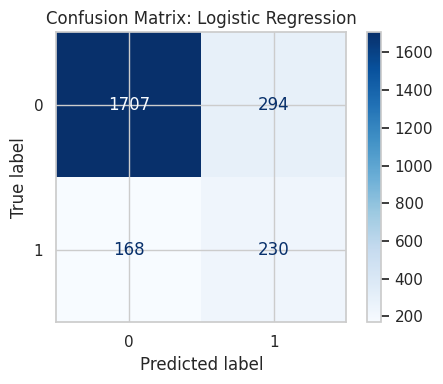


Confusion Matrix for Random Forest:


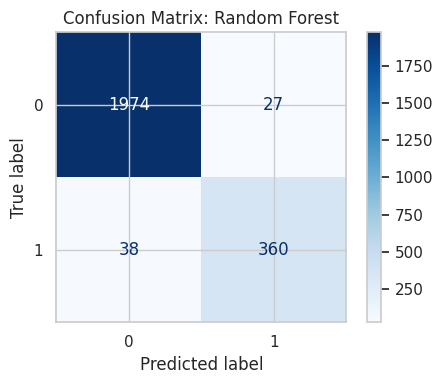


Confusion Matrix for Gradient Boosting:


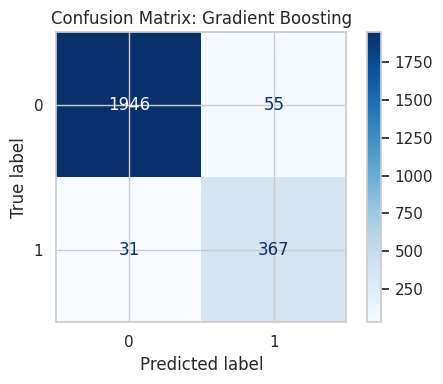


=== TASK 7: RETENTION ZONING & STRATEGIES ===

Employee Distribution across Risk Zones:
                      Employee Count  Percentage (%)
zone                                                
Safe (Green)                    1877           78.24
High Risk (Red)                  332           13.84
Low Risk (Yellow)                151            6.29
Medium Risk (Orange)              39            1.63

Pipeline execution complete successfully!


In [1]:
# ==========================================
# IMPORT LIBRARIES
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, ConfusionMatrixDisplay

from imblearn.over_sampling import SMOTE

# Set display options for clarity
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

print("--- Libraries Loaded Successfully ---")


# ==========================================
# TASK 1: DATA QUALITY CHECKS & CLEANING
# ==========================================
def loadAndCleanData(filePath):
  df = pd.read_csv(filePath)

  if 'sales' in df.columns:
      df = df.rename(columns={'sales': 'Department'})

  print("=== TASK 1: DATA QUALITY CHECKS ===")
  print(f"Initial Dataset Shape: {df.shape}")

  print("\nData Info:")
  print(df.info())

  missingVals = df.isnull().sum()
  print("\nMissing Values per Column:")
  print(missingVals)

  dupCount = df.duplicated().sum()
  print(f"\nNumber of duplicate rows found: {dupCount}")

  df = df.drop_duplicates().reset_index(drop=True)
  print(f"Dataset Shape after dropping duplicates: {df.shape}")

  print("\nBasic Statistics:")
  print(df.describe())

  return df

dfData = loadAndCleanData('/content/HR_comma_sep.csv')


# ==========================================
# TASK 2: EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================
def runEda(df):
  print("\n=== TASK 2: EXPLORATORY DATA ANALYSIS ===")

  plt.figure(figsize=(10, 7))
  corrMatrix = df.select_dtypes(include='number').corr()
  sns.heatmap(corrMatrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
  plt.title('Correlation Heatmap')
  plt.tight_layout()
  plt.show()

  fig, ax = plt.subplots(1, 3, figsize=(18, 5))
  sns.histplot(df['satisfaction_level'], kde=True, ax=ax[0], color='skyblue')
  ax[0].set_title('Employee Satisfaction Distribution')

  sns.histplot(df['last_evaluation'], kde=True, ax=ax[1], color='salmon')
  ax[1].set_title('Last Evaluation Distribution')

  sns.histplot(df['average_montly_hours'], kde=True, ax=ax[2], color='seagreen')
  ax[2].set_title('Average Monthly Hours Distribution')
  plt.tight_layout()
  plt.show()

  plt.figure(figsize=(8, 5))
  sns.countplot(data=df, x='number_project', hue='left', palette='Set2')
  plt.title('Project Count: Stayed vs Left')
  plt.xlabel('Number of Projects')
  plt.ylabel('Employee Count')
  plt.tight_layout()
  plt.show()

runEda(dfData)


# ==========================================
# TASK 3: CLUSTERING EMPLOYEES WHO LEFT
# ==========================================
def clusterLeavers(df):
  print("\n=== TASK 3: CLUSTERING EMPLOYEES WHO LEFT ===")

  leftEmp = df[df['left'] == 1][['satisfaction_level', 'last_evaluation']].copy()

  kmeansModel = KMeans(n_clusters=3, random_state=123, n_init=10)
  leftEmp['cluster'] = kmeansModel.fit_predict(leftEmp)

  plt.figure(figsize=(8, 6))
  sns.scatterplot(data=leftEmp, x='satisfaction_level', y='last_evaluation', hue='cluster', palette='Set1', alpha=0.7)
  plt.scatter(kmeansModel.cluster_centers_[:, 0], kmeansModel.cluster_centers_[:, 1], c='black', marker='X', s=250, label='Centroids')
  plt.title('K-Means Clustering of Leavers (k=3)')
  plt.xlabel('Satisfaction Level')
  plt.ylabel('Last Evaluation')
  plt.legend()
  plt.tight_layout()
  plt.show()

  clusterProfile = leftEmp.groupby('cluster').agg(['mean', 'count'])
  print("\nCluster Profiles:")
  print(clusterProfile)

  return leftEmp

clusteredLeavers = clusterLeavers(dfData)


# ==========================================
# TASK 4: HANDLE CLASS IMBALANCE WITH SMOTE
# ==========================================
def prepareDataAndSmote(df):
  print("\n=== TASK 4: ENCODING & SMOTE BALANCING ===")

  catCols = df[['Department', 'salary']]
  numCols = df.drop(columns=['Department', 'salary'])

  catDummies = pd.get_dummies(catCols, drop_first=False, dtype=int)
  dfFinal = pd.concat([numCols, catDummies], axis=1)

  print(f"Dataset shape after encoding: {dfFinal.shape}")

  featureMatrix = dfFinal.drop(columns='left')
  targetVector = dfFinal['left']

  xTrain, xTest, yTrain, yTest = train_test_split(
      featureMatrix, targetVector, test_size=0.20, stratify=targetVector, random_state=123
  )
  print(f"xTrain shape: {xTrain.shape}, xTest shape: {xTest.shape}")

  smoteSampler = SMOTE(random_state=123)
  xTrainSm, yTrainSm = smoteSampler.fit_resample(xTrain, yTrain)

  print("Class counts before SMOTE in train set:\n", yTrain.value_counts())
  print("Class counts after SMOTE in train set:\n", yTrainSm.value_counts())

  return xTrainSm, xTest, yTrainSm, yTest

xTrainSm, xTest, yTrainSm, yTest = prepareDataAndSmote(dfData)


# ==========================================
# TASK 5: TRAIN 3 MODELS WITH 5-FOLD CV
# ==========================================
def trainAndEvaluateModels(xTrainData, yTrainData):
  print("\n=== TASK 5: 5-FOLD CROSS-VALIDATION TRAINING ===")

  modelsMap = {
      'Logistic Regression': LogisticRegression(max_iter=1000, random_state=123),
      'Random Forest': RandomForestClassifier(random_state=123),
      'Gradient Boosting': GradientBoostingClassifier(random_state=123)
  }

  stratifiedKFold = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
  trainedModelsMap = {}

  for modelName, modelObj in modelsMap.items():
      print(f"\n--- Model: {modelName} ---")
      cvScores = cross_val_score(modelObj, xTrainData, yTrainData, cv=stratifiedKFold, scoring='recall')
      print(f"5-Fold CV Recall Scores: {cvScores.round(3)}")
      print(f"Mean CV Recall: {cvScores.mean():.3f} (+/- {cvScores.std():.3f})")

      yCvPred = cross_val_predict(modelObj, xTrainData, yTrainData, cv=stratifiedKFold)
      print("Classification Report (CV):")
      print(classification_report(yTrainData, yCvPred))

      modelObj.fit(xTrainData, yTrainData)
      trainedModelsMap[modelName] = modelObj

  return trainedModelsMap

modelsDict = trainAndEvaluateModels(xTrainSm, yTrainSm)


# ==========================================
# TASK 6: IDENTIFY THE BEST MODEL (ROC/AUC)
# ==========================================
def evaluateBestModel(modelsMap, testFeatures, testLabels):
  print("\n=== TASK 6: MODEL COMPARISON & ROC/AUC ===")

  plt.figure(figsize=(9, 7))

  for modelName, modelObj in modelsMap.items():
      predictedProbabilities = modelObj.predict_proba(testFeatures)[:, 1]
      aucScore = roc_auc_score(testLabels, predictedProbabilities)
      falsePositiveRate, truePositiveRate, _ = roc_curve(testLabels, predictedProbabilities)
      plt.plot(falsePositiveRate, truePositiveRate, label=f'{modelName} (AUC = {aucScore:.3f})', linewidth=2)

  plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.5)')
  plt.title('ROC Curves Comparison on Test Set')
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate (Recall)')
  plt.legend(loc='lower right')
  plt.tight_layout()
  plt.show()

  for modelName, modelObj in modelsMap.items():
      print(f"\nConfusion Matrix for {modelName}:")
      fig, ax = plt.subplots(figsize=(5, 4))
      ConfusionMatrixDisplay.from_estimator(modelObj, testFeatures, testLabels, cmap='Blues', ax=ax)
      plt.title(f'Confusion Matrix: {modelName}')
      plt.tight_layout()
      plt.show()

evaluateBestModel(modelsDict, xTest, yTest)


# ==========================================
# TASK 7: RETENTION STRATEGIES & RISK ZONING
# ==========================================
def generateRiskZones(modelsMap, testFeatures):
  print("\n=== TASK 7: RETENTION ZONING & STRATEGIES ===")

  bestModel = modelsMap['Random Forest']

  testResultDf = testFeatures.copy()
  testResultDf['probLeave'] = bestModel.predict_proba(testFeatures)[:, 1]

  testResultDf['zone'] = pd.cut(
      testResultDf['probLeave'],
      bins=[0.0, 0.2, 0.6, 0.9, 1.0],
      labels=['Safe (Green)', 'Low Risk (Yellow)', 'Medium Risk (Orange)', 'High Risk (Red)'],
      include_lowest=True
  )

  zoneCounts = testResultDf['zone'].value_counts()
  zonePercentages = testResultDf['zone'].value_counts(normalize=True) * 100

  zoneSummaryDf = pd.DataFrame({
      'Employee Count': zoneCounts,
      'Percentage (%)': zonePercentages.round(2)
  })

  print("\nEmployee Distribution across Risk Zones:")
  print(zoneSummaryDf)

  return testResultDf

riskDf = generateRiskZones(modelsDict, xTest)
print("\nPipeline execution complete successfully!")